Дицель Н.С. ИКБО-11-23

Информационные системы мониторинга и управления инцидентами

# Практическая работа 5. Инструменты анализа пакетов

In [1]:
%pip install -q --disable-pip-version-check scapy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import logging
logging.getLogger("scapy").setLevel(logging.ERROR)

import os
import urllib.request
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt
from scapy.all import rdpcap, wrpcap, Ether, IP, IPv6, TCP, UDP, ICMP, DNS, DNSQR

## Домашнее задание 1. Статистический анализ PCAP-файла

Файл `nb6-startup.pcap` из [Wireshark Sample Captures](https://wiki.wireshark.org/SampleCaptures): включение домашнего роутера.

In [3]:
FILE_NAME = "nb6-startup.pcap"
URL = "https://wiki.wireshark.org/uploads/__moin_import__/attachments/SampleCaptures/" + FILE_NAME

if not os.path.exists(FILE_NAME):
    urllib.request.urlretrieve(URL, FILE_NAME)

packets = rdpcap(FILE_NAME)
total = len(packets)
print("Пакетов:", total)

Пакетов:

531

### Протоколы

IPv6 в дампе идёт внутри туннеля (IPv4 → UDP → L2TP → IPv6), а `haslayer()` ищет слой на любой глубине. Поэтому считаю по внешнему IP-заголовку.

In [4]:
def outer_ip(pkt):
    for layer in pkt.layers():
        if layer in (IP, IPv6):
            return pkt[layer]
    return None


def transport_of(pkt):
    ip = outer_ip(pkt)
    if ip is None:
        return "Не-IP"
    payload = ip.payload
    while payload.__class__.__name__.startswith("IPv6ExtHdr"):
        payload = payload.payload
    if isinstance(payload, TCP):
        return "TCP"
    if isinstance(payload, UDP):
        return "UDP"
    if isinstance(payload, ICMP):
        return "ICMP"
    if payload.__class__.__name__.startswith("ICMPv6"):
        return "ICMPv6"
    return "Другой IP"


outer = Counter(type(outer_ip(p)).__name__ if outer_ip(p) is not None else "Без IP" for p in packets)
tunneled_v6 = sum(1 for p in packets if isinstance(outer_ip(p), IP) and p.haslayer(IPv6))
transport = Counter(transport_of(p) for p in packets)

net_df = pd.DataFrame(
    {"Пакетов": [outer.get("IP", 0), outer.get("IPv6", 0), outer.get("Без IP", 0), tunneled_v6]},
    index=["IPv4", "IPv6", "Без IP", "IPv6 в туннеле"],
)
net_df["Доля, %"] = (net_df["Пакетов"] / total * 100).round(1)

order = ["TCP", "UDP", "ICMP", "ICMPv6", "Другой IP", "Не-IP"]
proto_df = pd.DataFrame({"Пакетов": [transport.get(k, 0) for k in order]}, index=order)
proto_df["Доля, %"] = (proto_df["Пакетов"] / total * 100).round(1)

display(net_df)
display(proto_df)

,Пакетов,"Доля, %"
IPv4,370,69.7
IPv6,0,0.0
Без IP,161,30.3
IPv6 в туннеле,10,1.9


,Пакетов,"Доля, %"
TCP,116,21.8
UDP,249,46.9
ICMP,2,0.4
ICMPv6,0,0.0
Другой IP,3,0.6
Не-IP,161,30.3


In [5]:
non_ip = [p for p in packets if outer_ip(p) is None]
pd.DataFrame(Counter(p.layers()[1].__name__ for p in non_ip).most_common(), columns=["Без IP", "Пакетов"])

,Без IP,Пакетов
0,ARP,89
1,PPPoE,56
2,PPPoED,16


### Топ-5 IP-адресов

In [6]:
src, dst = Counter(), Counter()
for p in packets:
    ip = outer_ip(p)
    if ip is not None:
        src[ip.src] += 1
        dst[ip.dst] += 1

display(pd.DataFrame(src.most_common(5), columns=["Источник", "Пакетов"]))
display(pd.DataFrame(dst.most_common(5), columns=["Назначение", "Пакетов"]))

,Источник,Пакетов
0,10.251.23.139,84
1,95.136.242.99,74
2,109.0.66.10,56
3,86.66.0.227,50
4,109.6.1.72,46


,Назначение,Пакетов
0,95.136.242.99,80
1,10.251.23.139,68
2,86.66.0.227,66
3,109.0.66.10,56
4,109.6.1.72,40


### Размер пакетов

In [7]:
sizes = pd.Series([len(p) for p in packets])
pd.DataFrame({"Байт": [sizes.min(), sizes.max(), round(sizes.mean(), 1)]}, index=["min", "max", "среднее"])

,Байт
min,30.0
max,1510.0
среднее,148.1


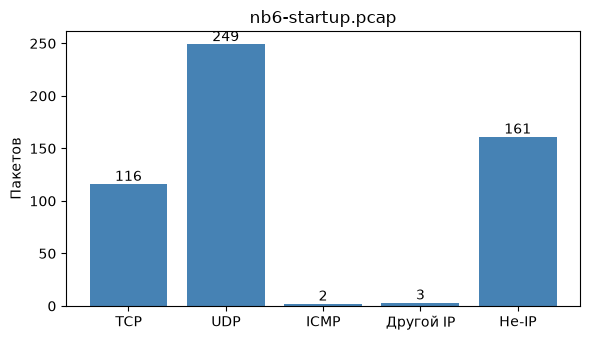

In [8]:
plot_df = proto_df[proto_df["Пакетов"] > 0]

plt.figure(figsize=(6, 3.5))
plt.bar_label(plt.bar(plot_df.index, plot_df["Пакетов"], color="steelblue"))
plt.ylabel("Пакетов")
plt.title(FILE_NAME)
plt.tight_layout()
plt.show()

### Вывод

- 531 пакет: IPv4 — 370 (70%), без IP — 161 (30%: ARP, PPPoE, PPPoED). Роутер поднимает PPPoE-сессию.
- Больше всего UDP — 249 (47%): DNS 112, L2TP 86, NTP 34.
- TCP — 116 (22%), всё на порт 80, это загрузка конфигурации по HTTP.
- Самые активные: 10.251.23.139 (HTTP с 86.66.0.227) и 95.136.242.99 (DNS и L2TP, видимо внешний адрес роутера).
- Пакеты в основном мелкие: в среднем 148 байт, максимум 1510.
- Ограничения: дамп один и снят только при запуске роутера. IPv6 есть только внутри L2TP-туннеля (10 пакетов). Полезную нагрузку не разбирал.

## Домашнее задание 2. Обнаружение SYN-сканирования

Синтетический дамп, пакеты только пишутся в файл.

| Источник | Что делает |
| :--- | :--- |
| 10.0.0.66 | SYN на 25 портов 10.0.0.10 без завершения рукопожатия |
| 10.0.0.10 | Отвечает сканеру SYN-ACK / RST |
| 10.0.0.35 | Мониторинг: полные соединения на 7 портов |
| 10.0.0.21 | 3 HTTPS-соединения |
| 10.0.0.47 | 8 повторов SYN на 8080 |
| 10.0.0.5 | DNS и ping |

In [9]:
SERVER = "10.0.0.10"
packets_out = []
t = 1_700_000_000.0


def add(pkt, dt=0.01):
    global t
    t += dt
    pkt.time = t
    packets_out.append(pkt)


def connect(client, server, sport, dport, data=False):
    # SYN, SYN-ACK, ACK, [данные], FIN
    add(Ether() / IP(src=client, dst=server) / TCP(sport=sport, dport=dport, flags="S", seq=1000))
    add(Ether() / IP(src=server, dst=client) / TCP(sport=dport, dport=sport, flags="SA", seq=5000, ack=1001))
    add(Ether() / IP(src=client, dst=server) / TCP(sport=sport, dport=dport, flags="A", seq=1001, ack=5001))
    if data:
        add(Ether() / IP(src=client, dst=server) / TCP(sport=sport, dport=dport, flags="PA", seq=1001, ack=5001) / (b"x" * 200))
    add(Ether() / IP(src=client, dst=server) / TCP(sport=sport, dport=dport, flags="FA", seq=1201, ack=5001))


for i, port in enumerate(range(20, 45)):
    sport = 40000 + i
    add(Ether() / IP(src="10.0.0.66", dst=SERVER) / TCP(sport=sport, dport=port, flags="S"), dt=0.002)
    reply = "SA" if port in (22, 80, 443) else "RA"
    add(Ether() / IP(src=SERVER, dst="10.0.0.66") / TCP(sport=port, dport=sport, flags=reply), dt=0.001)

for i, port in enumerate([22, 80, 443, 3000, 9090, 9100, 9200]):
    connect("10.0.0.35", SERVER, 50000 + i, port)

for i in range(3):
    connect("10.0.0.21", "203.0.113.10", 51000 + i, 443, data=True)

for i in range(8):
    add(Ether() / IP(src="10.0.0.47", dst=SERVER) / TCP(sport=52000, dport=8080, flags="S"), dt=1.0)

for name in ["example.com", "example.org"]:
    add(Ether() / IP(src="10.0.0.5", dst="10.0.0.1") / UDP(sport=53000, dport=53) / DNS(rd=1, qd=DNSQR(qname=name)))
for i in range(3):
    add(Ether() / IP(src="10.0.0.5", dst="10.0.0.1") / ICMP(id=1, seq=i))

SYN_FILE = "syn_test_traffic.pcap"
wrpcap(SYN_FILE, packets_out)
print(f"{len(packets_out)} пакетов -> {SYN_FILE}")

106 пакетов -> syn_test_traffic.pcap

### Статистика по источникам

SYN-ACK — ответ сервера, поэтому в правиле учитываются только SYN без ACK.

In [10]:
def syn_stats(path):
    stats = defaultdict(lambda: {"TCP": 0, "SYN": 0, "SYN без ACK": 0, "ports": set()})

    for p in rdpcap(path):
        if not p.haslayer(TCP):
            continue
        ip = outer_ip(p)
        if ip is None:
            continue
        flags = p[TCP].flags
        s = stats[ip.src]
        s["TCP"] += 1
        if flags.S:
            s["SYN"] += 1
            if not flags.A:
                s["SYN без ACK"] += 1
                s["ports"].add(p[TCP].dport)

    if not stats:
        print(f"В {path} TCP-пакетов не найдено")
        return None

    df = pd.DataFrame.from_dict(stats, orient="index")
    df["Портов"] = df.pop("ports").apply(len)
    df.index.name = "Источник"
    return df.sort_values("SYN без ACK", ascending=False)


def is_suspicious(df, min_syn=5, min_ports=5):
    return (df["SYN без ACK"] >= min_syn) & (df["Портов"] >= min_ports)


syn_df = syn_stats(SYN_FILE)
syn_df

,TCP,SYN,SYN без ACK,Портов
Источник,,,,
10.0.0.66,25,25,25,25
10.0.0.47,8,8,8,1
10.0.0.35,21,7,7,7
10.0.0.21,12,3,3,1
10.0.0.10,32,8,0,0
203.0.113.10,3,3,0,0


In [11]:
THRESHOLDS = [(5, 5), (10, 10)]  # (SYN, порты)

result = syn_df.copy()
for min_syn, min_ports in THRESHOLDS:
    result[f"{min_syn}/{min_ports}"] = is_suspicious(result, min_syn, min_ports).map({True: "да", False: "нет"})
result

,TCP,SYN,SYN без ACK,Портов,5/5,10/10
Источник,,,,,,
10.0.0.66,25,25,25,25,да,да
10.0.0.47,8,8,8,1,нет,нет
10.0.0.35,21,7,7,7,да,нет
10.0.0.21,12,3,3,1,нет,нет
10.0.0.10,32,8,0,0,нет,нет
203.0.113.10,3,3,0,0,нет,нет


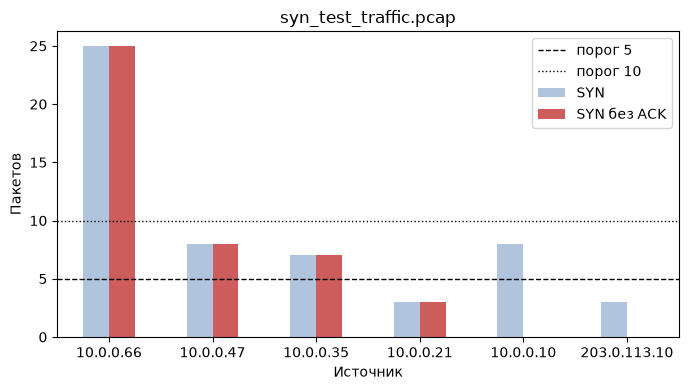

In [12]:
ax = syn_df[["SYN", "SYN без ACK"]].plot.bar(figsize=(7, 4), color=["lightsteelblue", "indianred"], rot=0)
for (min_syn, _), style in zip(THRESHOLDS, ["--", ":"]):
    ax.axhline(min_syn, color="black", linestyle=style, linewidth=1, label=f"порог {min_syn}")
ax.set_ylabel("Пакетов")
ax.set_title(SYN_FILE)
ax.legend()
plt.tight_layout()
plt.show()

Дамп без TCP:

In [13]:
dns_only = Ether() / IP(src="10.0.0.5", dst="10.0.0.1") / UDP(sport=53000, dport=53) / DNS(qd=DNSQR(qname="example.com"))
wrpcap("udp_only.pcap", [dns_only])
syn_stats("udp_only.pcap")

В udp_only.pcap TCP-пакетов не найдено

### Заключение

- Порог 5/5 сработал на 10.0.0.66 (25 SYN на 25 портов) и 10.0.0.35 (7 на 7), порог 10/10 — только на 10.0.0.66.
- 10.0.0.35 — мониторинг, соединения завершаются, так что при 5/5 это ложное срабатывание.
- 10.0.0.47 отправил 8 SYN на один порт. Это повторы подключения, и правило отсекло их по числу портов.
- 10.0.0.10 отправил 8 SYN-ACK. Если не исключать ACK, отвечающий сервер тоже попадёт в сканеры.

Почему правило не доказывает атаку:

- Тот же рисунок дают мониторинг (blackbox-exporter, Zabbix), сканеры уязвимостей (Nessus, MaxPatrol), health-check балансировщиков и клиенты, которые переподключаются при сбое.
- В правиле нет временного окна: медленное сканирование или сканирование с нескольких адресов под порог не попадёт.
- Один PCAP показывает только точку съёма, и контекста в нём нет: чей это адрес, были ли плановые работы.

Срабатывание — повод проверить источник, но не доказательство атаки.